In [100]:
import numpy as np
import netCDF4 as nc
import xarray as xr
import os
import json
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.lines as mlines
from matplotlib.colors import TwoSlopeNorm
import pandas as pd
import cartopy.crs as ccrs
from ladcp_tools import *                  # load_all_stations, ...
from tools import *                        # setup_map, load_satellite, load_eddies, plot_eddies

In [ ]:
EXTENT = None  # e.g. [10, 20, -42, -34]
lon_min, lon_max, lat_min, lat_max = 8, 25, -41, -34
extent = [lon_min, lon_max, lat_min, lat_max]

CRUISE_START = "2026-05-14"
CRUISE_END   = "2026-07-27"

ft = 10
# ADT colours: white exactly at 0, but each side stretched separately
# (ADT here is ~ -0.3 .. +1.5 m). Lower ADT_MIN -> darker cyclone blues,
# raise ADT_MAX -> fewer saturated anticyclone reds.
ADT_MIN, ADT_MAX = -0.3, 1.5
adt_norm = TwoSlopeNorm(vmin=ADT_MIN, vcenter=0, vmax=ADT_MAX)
levels = np.arange(ADT_MIN, ADT_MAX + 0.001, 0.02)
adt_ticks = [-0.3, 0, 0.3, 0.6, 0.9, 1.2, 1.5]

crs = ccrs.PlateCarree()
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max) / 2)


BASE = Path("/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS")
DIR_SADCP = BASE / "data/SADCP"
SADCP_FILES = {"OS150": DIR_SADCP / "WHIRLS_NB150_TOT_osite.nc",   # full cruise (README)
               "OS38": DIR_SADCP / "WHIRLS_BB38_TOT_osite.nc"}
DIR_LADCP = BASE / "data/LADCP/traitement_avec_SADCP"
DIR_SSH = BASE / "data/SSH"
DIR_EDDIES = {"TOEDDIES_better_ADT": BASE / "data/TOEDDIES/TOEDDIES_better_ADT",
              "TOEDDIES": BASE / "data/TOEDDIES/TOEDDIES"}
FNAME_BATHY = BASE / "data/bathymetry/etopo2.nc"
DIR_TRACKS = BASE / "figures/eddy_tracks"
DIR_CODE = BASE / "analysis"          # where ladcp_tools.py lives

DIR_DRIFTERS =  BASE / "data/DRIFTERS/drifters"
DIR_GEOJSON = BASE / "data/DRIFTERS/drifters_tracks.geojson"

# Animation
ANIM_START = "2026-07-01"                 # first drifter deployment
ANIM_END   = CRUISE_END                   # days without an ADT file are skipped
TAIL_DAYS  = 5                            # length of the track drawn behind each drifter (None = whole track)

# Drifter data: "csv" (folder of CSV snapshots, DIR_DRIFTERS) or "geojson" (DIR_GEOJSON)
DRIFTER_SOURCE = "csv"
FIRST_LAUNCH = "2026-07-01 05:00"         # fixes before this are bench tests (as in Solange's script)
FRAME_DIR = "whirls_drifters_animation"
OUT_MP4   = "whirls_drifters_animation.mp4"
FPS = 2                                   # frames (days) per second

os.makedirs(FRAME_DIR, exist_ok=True)

In [102]:
# ----------------------------------------------------------------------------
# Things loaded ONCE (they don't change from day to day)
# ----------------------------------------------------------------------------
# Bathymetry
bathymetry_data = xr.open_dataset(FNAME_BATHY)
lon_subset = bathymetry_data["lon"].sel(lon=slice(lon_min, lon_max))
lat_subset = bathymetry_data["lat"].sel(lat=slice(lat_min, lat_max))
depth_subset = bathymetry_data["topo"].sel(lon=slice(lon_min, lon_max),
                                           lat=slice(lat_min, lat_max))

# File lists
daily_ssh_files = sorted(os.listdir(DIR_SSH))
eddy_files_better = sorted(os.listdir(DIR_EDDIES['TOEDDIES_better_ADT']))
eddy_files_std = sorted(os.listdir(DIR_EDDIES['TOEDDIES']))


In [ ]:
def get_eddy_files(date_compact, date):
    """Use the better-ADT TOEddies when available for that day, else the standard ones."""
    files = [DIR_EDDIES['TOEDDIES_better_ADT'] / f for f in eddy_files_better if date_compact in f]
    if files:
        return files, "TOEddies (better ADT)"
    files = [DIR_EDDIES['TOEDDIES'] / f for f in eddy_files_std if date in f]
    if files:
        return files, "TOEddies (standard)"
    return [], None


def find_time_column(df):
    """Return the name of the column holding the cast time."""
    for cand in ["time", "date", "datetime", "start_time", "time_start", "t"]:
        if cand in df.columns:
            return cand
    for c in df.columns:                       # any datetime-typed column
        if np.issubdtype(df[c].dtype, np.datetime64):
            return c
    raise KeyError(
        "No time column found in the LADCP station table. "
        f"Columns are: {list(df.columns)}. "
        "Add the cast time in load_all_stations() or set TIME_COL by hand."
    )


## Drifters
`drifters_tracks.geojson` holds three kinds of feature per drifter (`D_number`):
* `kind="track"`: one LineString with every position but **no times**
* `kind="track_segment"`: ~220 two-point LineStrings, each with `start_date` → `end_date`
* `kind="latest_position"`: one Point

So 200 drifters × ~220 segments = the 44 064 features. Times only exist on the segments, so the fixes
are rebuilt from them. The `speed_mps` property is unreliable (up to 553 m/s), so speeds are recomputed from positions.

The CSV files (`DIR_DRIFTERS`) hold the same fixes as snapshots, plus the drifter velocity
(`u_speed`, `u_dir`). Pick one with `DRIFTER_SOURCE` in the settings cell; the next cells
are identical for both.

In [104]:
def _dist_m(lon1, lat1, lon2, lat2):
    R = 6371e3
    lon1, lat1, lon2, lat2 = map(np.deg2rad, (lon1, lat1, lon2, lat2))
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * R * np.arcsin(np.sqrt(a))


def _add_speed(df):
    """Speed (m/s) and gap (h) from each fix to the NEXT fix of the same drifter."""
    g = df.groupby("id")
    lon2, lat2, t2 = g["lon"].shift(-1), g["lat"].shift(-1), g["time"].shift(-1)
    df["dt_h"] = (t2 - df["time"]).dt.total_seconds() / 3600
    df["speed"] = _dist_m(df["lon"], df["lat"], lon2, lat2) / (df["dt_h"] * 3600)
    return df


def read_drifter_geojson(path):
    """
    The geojson has, per drifter (D_number):
      kind='track'           : one LineString with all positions, NO times
      kind='track_segment'   : 2-point LineStrings, start_date -> end_date
      kind='latest_position' : one Point
    Times only live on the segments, so fixes are rebuilt from them:
    every segment start + the end of the last segment.
    Returns DataFrame [id, time, lon, lat] sorted by id, time.
    """
    with open(path) as f:
        feats = json.load(f)["features"]

    rows = []
    for ft in feats:
        p = ft["properties"]
        if p.get("kind") != "track_segment":
            continue
        (lon0, lat0), (lon1, lat1) = [c[:2] for c in ft["geometry"]["coordinates"]]
        rows.append((p["D_number"], p["start_date"], lon0, lat0))
        rows.append((p["D_number"], p["end_date"], lon1, lat1))

    df = pd.DataFrame(rows, columns=["id", "time", "lon", "lat"])
    df["time"] = pd.to_datetime(df["time"], utc=True).dt.tz_localize(None)
    df = (df.drop_duplicates(["id", "time"])
            .sort_values(["id", "time"]).reset_index(drop=True))
    return df


def clean_drifters(df, max_deploy_speed=1.5, max_gap_days=2, spike_speed=3.0,
                   match_hours=6, match_km=25):
    """
    Finds each drifter's deployment and drops fixes taken before it (on deck /
    on the ship), then removes GPS spikes. Adds 'deploy_time' and 'launch' columns.

    1) "Clear" starts: the first step is slow (< max_deploy_speed m/s, i.e. not
       ship speed) and the next fix comes within max_gap_days. Those first fixes
       define deployment events (clustered within match_hours / match_km).
    2) Every drifter: deployment = first fix that either matches an event, or
       starts a clear (slow, regular) step. Earlier fixes are dropped. This keeps
       drifters that were deployed with a group but stayed silent for days.
    3) Spikes: drop isolated fixes with speed in AND out > spike_speed m/s.
    """
    df = _add_speed(df.copy())
    clear = (df["speed"] < max_deploy_speed) & (df["dt_h"] < max_gap_days * 24)

    # --- 1) deployment events from drifters whose very first step is clear
    first = df.groupby("id").head(1)
    first = first[clear.loc[first.index]].sort_values("time")
    events = []                                   # [time, lon, lat, n]
    for _, r in first.iterrows():
        for e in events:
            if (abs((r.time - e[0]).total_seconds()) < match_hours * 3600
                    and _dist_m(r.lon, r.lat, e[1], e[2]) < match_km * 1e3):
                e[3] += 1
                break
        else:
            events.append([r.time, r.lon, r.lat, 1])
    ev = pd.DataFrame(events, columns=["time", "lon", "lat", "n"])

    def near_event(r):
        dt = (ev["time"] - r.time).abs().dt.total_seconds()
        d = _dist_m(r.lon, r.lat, ev["lon"].values, ev["lat"].values)
        m = (dt < match_hours * 3600) & (d < match_km * 1e3)
        return ev.loc[m, "time"].iloc[0] if m.any() else pd.NaT

    # --- 2) per drifter: first fix that matches an event or starts a clear step
    keep = []
    for did, g in df.groupby("id", sort=False):
        start, launch = None, pd.NaT
        for i, (idx, r) in enumerate(g.iterrows()):
            launch = near_event(r)
            if pd.notna(launch) or clear[idx]:
                start = i
                break
        if start is None:
            continue
        g = g.iloc[start:].copy()
        g["launch"] = launch if pd.notna(launch) else g["time"].iloc[0]
        keep.append(g)
    df = pd.concat(keep).reset_index(drop=True)

    # --- 3) spikes
    for _ in range(3):
        df = _add_speed(df)
        speed_in = df.groupby("id")["speed"].shift(1)
        spike = (df["speed"] > spike_speed) & (speed_in > spike_speed)
        if not spike.any():
            break
        df = df[~spike].reset_index(drop=True)
    df = _add_speed(df)
    df["deploy_time"] = df.groupby("id")["time"].transform("min")
    return df


def deployments(df):
    """One row per deployment event: date, position, number of drifters, ids."""
    first = df.groupby("id").first().reset_index()
    return (first.groupby("launch")
                 .agg(n_drifters=("id", "size"),
                      lon=("lon", "median"), lat=("lat", "median"),
                      ids=("id", lambda s: ", ".join(sorted(s))))
                 .reset_index())


def read_drifter_csvs(folder, first_launch=None):
    """
    CSV snapshots from GEOMAR (one file every 10-15 min). Each file has one row per
    drifter that reported:  D_number,date_UTC,Latitude,Longitude,U_speed_mps,U_Dir_deg,batteryState
    Longitudes < -1000 are missing positions. Not every file has every drifter.
    Returns DataFrame [id, time, lon, lat, u_speed, u_dir, battery] sorted by id, time.
    """
    cols = ["D_number", "date_UTC", "Latitude", "Longitude"]
    files = sorted(Path(folder).glob("*.csv"))
    dfs = []
    for f in files:
        try:
            d = pd.read_csv(f)
        except Exception:                      # empty / unreadable file
            continue
        if all(c in d.columns for c in cols):  # skip any merged/other csv in the folder
            dfs.append(d)
    print(f"{len(dfs)} of {len(files)} csv files read")
    df = pd.concat(dfs, ignore_index=True)

    df = df.rename(columns={"D_number": "id", "Latitude": "lat", "Longitude": "lon",
                            "U_speed_mps": "u_speed", "U_Dir_deg": "u_dir",
                            "batteryState": "battery"})
    df["time"] = pd.to_datetime(df["date_UTC"], format="%d-%b-%Y %H:%M:%S", errors="coerce")
    df = df[(df["lon"] > -1000) & df["time"].notna()]         # missing positions
    if first_launch is not None:
        df = df[df["time"] >= pd.Timestamp(first_launch)]
    df = (df.drop(columns="date_UTC")
            .drop_duplicates(["id", "time"])                  # same fix repeated in later files
            .sort_values(["id", "time"]).reset_index(drop=True))
    return df

In [106]:
DIR_DRIFTERS

PosixPath('/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/DRIFTERS/drifters')

In [ ]:
if DRIFTER_SOURCE == "csv":
    raw = read_drifter_csvs(DIR_DRIFTERS, first_launch=FIRST_LAUNCH)
else:
    raw = read_drifter_geojson(DIR_GEOJSON)
drift = clean_drifters(raw)
print(f"{raw['id'].nunique()} drifters, {len(raw)} fixes -> {len(drift)} after removing on-deck fixes and spikes")
print(f"fixes every ~{drift['dt_h'].median():.1f} h, {drift['time'].min():%d %b} -> {drift['time'].max():%d %b %Y}")

# Deployment groups (by day)
drift["launch_day"] = drift["launch"].dt.floor("D")
launch_days = sorted(drift["launch_day"].unique())
summary = (drift.groupby("id").first().reset_index()
                .groupby("launch_day")
                .agg(n_drifters=("id", "size"), lon=("lon", "median"), lat=("lat", "median"),
                     first_id=("id", "min"), last_id=("id", "max")))
summary

2719 of 2719 csv files read
200 drifters, 436997 fixes -> 434987 after removing on-deck fixes and spikes
fixes every ~1.1 h, 01 Jul -> 28 Oct 2026


,n_drifters,lon,lat,first_id,last_id
launch_day,,,,,
2026-07-01,32,12.829605,-36.817525,D-503,D-630
2026-07-02,22,11.937290,-38.520920,D-433,D-550
2026-07-03,4,11.541600,-38.475945,D-566,D-592
2026-07-09,11,11.282940,-37.778750,D-441,D-613
2026-07-10,73,12.106250,-37.317810,D-432,D-624
2026-07-13,1,12.939020,-35.501980,D-455,D-455
2026-07-16,12,13.857075,-36.494125,D-535,D-622
2026-07-20,45,11.503440,-39.714400,D-431,D-629


/Users/emmagurcan/Library/Python/3.9/lib/python/site-packages/cartopy/io/__init__.py:241: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


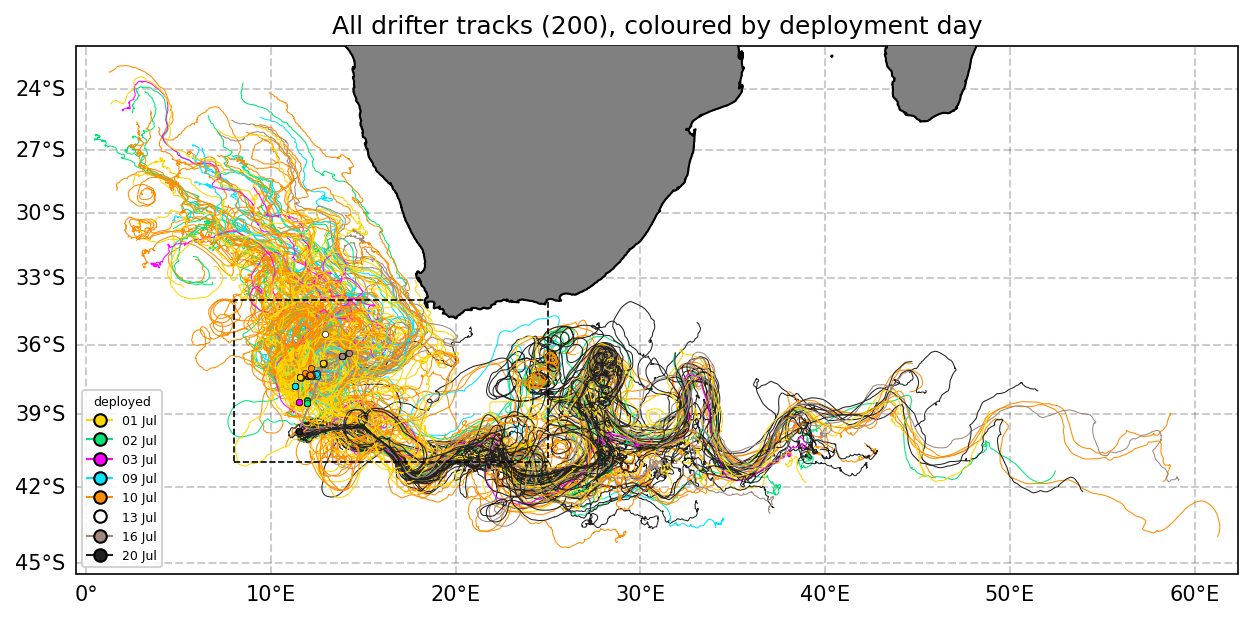

In [111]:
# One colour per deployment day (avoiding red/blue so they show on the ADT map)
LAUNCH_COLORS = ["#ffd700", "#00e676", "#ff00ff", "#00e5ff", "#ff8c00",
                 "#ffffff", "#a1887f", "#212121", "#b2ff59", "#ea80fc"]
launch_color = {d: LAUNCH_COLORS[i % len(LAUNCH_COLORS)] for i, d in enumerate(launch_days)}
drifter_color = drift.groupby("id")["launch_day"].first().map(launch_color)

# Overview: every trajectory over the whole record, coloured by deployment day
big = [drift.lon.min() - 1, drift.lon.max() + 1, drift.lat.min() - 1, drift.lat.max() + 1]
fig = plt.figure(figsize=(10, 5), dpi=150)
ax = fig.add_subplot(111, projection=ccrs.Mercator(central_longitude=np.mean(big[:2])))
setup_map(ax, big, f"All drifter tracks ({drift['id'].nunique()}), coloured by deployment day", crs, ft)
for did, g in drift.groupby("id"):
    c = drifter_color[did]
    ax.plot(g.lon, g.lat, color=c, lw=0.5, transform=crs)
    ax.plot(g.lon.iloc[0], g.lat.iloc[0], "o", ms=3, mfc=c, mec="k", mew=0.3, transform=crs, zorder=5)
ax.plot([lon_min, lon_max, lon_max, lon_min, lon_min], [lat_min, lat_min, lat_max, lat_max, lat_min],
        "k--", lw=0.8, transform=crs)           # animation box
ax.legend(handles=[mlines.Line2D([], [], color=launch_color[d], marker="o", mec="k", lw=1,
                                 label=f"{pd.Timestamp(d):%d %b}") for d in launch_days],
          title="deployed", fontsize=6, title_fontsize=6, loc="lower left", framealpha=0.85)
plt.show()

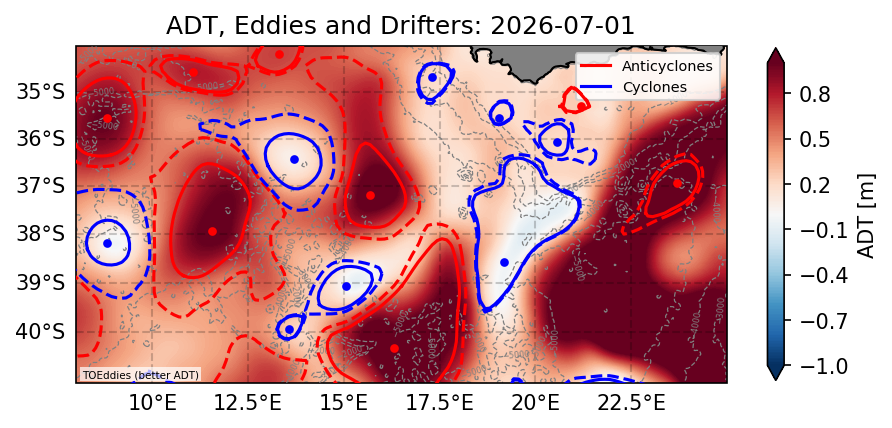

In [98]:
date = "2026-07-01"
date_str = date
date_compact = date.replace("-", "")

# --- ADT of the day ---
ssh_match = [f for f in daily_ssh_files if date_str in f or date_compact in f]

ssh = load_satellite(DIR_SSH / ssh_match[0])

# --- Eddies of the day ---
eddy_files, eddy_source = get_eddy_files(date_compact, date_str)

# Fixed figure size and no bbox_inches="tight" so all frames are identical in size
fig = plt.figure(figsize=(7, 4.8), dpi=150)
ax = fig.add_subplot(111, projection=proj)
setup_map(ax, extent, f"ADT, Eddies and Drifters: {date_str}", crs, ft)

bathy = ax.contour(lon_subset, lat_subset, depth_subset,
                    colors="grey", linewidths=0.6, transform=crs)
ax.clabel(bathy, fontsize=4)

c = ax.contourf(ssh["lon"], ssh["lat"], ssh["adt"][0],
                levels=levels, cmap="RdBu_r", extend="both",
                transform=crs)

if eddy_files:
    anti, cyc = load_eddies(eddy_files)
    plot_eddies(ax, anti, "red", crs)
    plot_eddies(ax, cyc, "blue", crs)
# Small label so you can see which eddy product each frame uses
if eddy_source:
    ax.text(0.01, 0.01, eddy_source, transform=ax.transAxes, fontsize=5,
            ha="left", va="bottom", zorder=102,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1))

# --- Legend (proxy handles, so it is the same on every frame) ---
handles = [
    mlines.Line2D([], [], color="red", label="Anticyclones"),
    mlines.Line2D([], [], color="blue", label="Cyclones"),
]
ax.legend(handles=handles, fontsize="x-small", loc="upper right",
            framealpha=0.85)

cb = fig.colorbar(c, ax=ax, shrink=0.6, ticks=np.arange(vmin, vmax + 0.01, 0.3))
cb.set_label("ADT [m]")
plt.show()


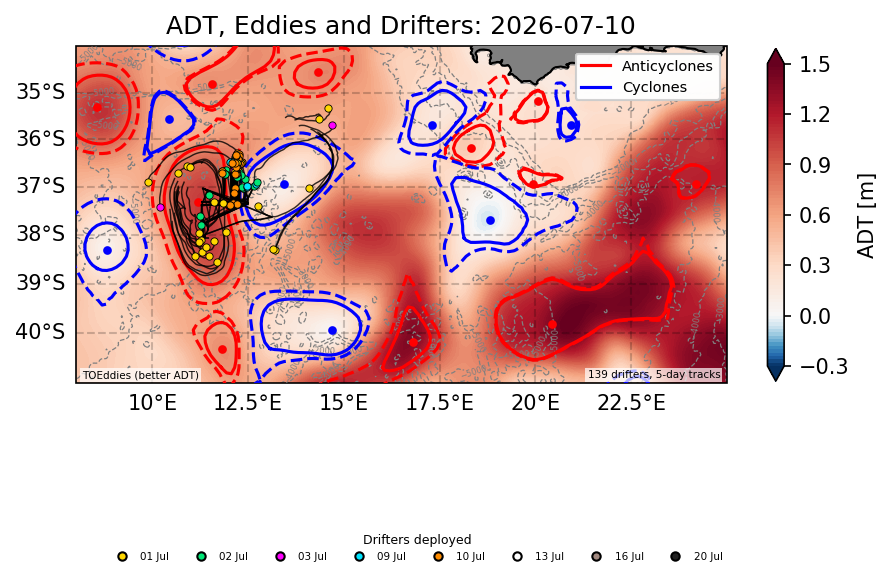

In [112]:
def plot_day(date, drift, tail_days=TAIL_DAYS):
    """Map of ADT, eddies and drifter tracks for one day. Returns fig (or None if no ADT file)."""
    date_str = pd.Timestamp(date).strftime("%Y-%m-%d")
    date_compact = date_str.replace("-", "")

    # --- ADT of the day ---
    ssh_match = [f for f in daily_ssh_files if date_str in f or date_compact in f]
    if not ssh_match:
        print(f"{date_str}: no ADT file, skipped")
        return None
    ssh = load_satellite(DIR_SSH / ssh_match[0])

    # --- Eddies of the day ---
    eddy_files, eddy_source = get_eddy_files(date_compact, date_str)

    # Fixed figure size and no bbox_inches="tight" so all frames are identical in size
    fig = plt.figure(figsize=(7, 4.8), dpi=150)
    ax = fig.add_subplot(111, projection=proj)
    setup_map(ax, extent, f"ADT, Eddies and Drifters: {date_str}", crs, ft)

    bathy = ax.contour(lon_subset, lat_subset, depth_subset,
                       colors="grey", linewidths=0.6, transform=crs)
    ax.clabel(bathy, fontsize=4)

    c = ax.contourf(ssh["lon"], ssh["lat"], ssh["adt"][0],
                    levels=levels, cmap="RdBu_r", norm=adt_norm, extend="both",
                    transform=crs)

    if eddy_files:
        anti, cyc = load_eddies(eddy_files)
        plot_eddies(ax, anti, "red", crs)
        plot_eddies(ax, cyc, "blue", crs)
    if eddy_source:
        ax.text(0.01, 0.01, eddy_source, transform=ax.transAxes, fontsize=5,
                ha="left", va="bottom", zorder=102,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1))

    # --- Drifters: track over the last `tail_days` days + position at the end of the day ---
    t_end = pd.Timestamp(date_str) + pd.Timedelta(days=1)
    now = drift[drift["time"] < t_end]
    if tail_days is not None:
        now = now[now["time"] >= t_end - pd.Timedelta(days=tail_days)]
    n_active = 0
    for did, g in now.groupby("id"):
        if t_end - g["time"].iloc[-1] > pd.Timedelta(days=2):
            continue                             # stopped transmitting
        n_active += 1
        ax.plot(g.lon, g.lat, color="k", lw=0.7, alpha=0.8, transform=crs, zorder=103)
        ax.plot(g.lon.iloc[-1], g.lat.iloc[-1], "o", ms=3.5, mfc=drifter_color[did],
                mec="k", mew=0.4, transform=crs, zorder=104)
    ax.text(0.99, 0.01, f"{n_active} drifters" + (f", {tail_days}-day tracks" if tail_days else ""),
            transform=ax.transAxes, fontsize=5, ha="right", va="bottom", zorder=105,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1))

    # --- Legends (proxy handles, so they are the same on every frame) ---
    eddy_handles = [mlines.Line2D([], [], color="red", label="Anticyclones"),
                    mlines.Line2D([], [], color="blue", label="Cyclones")]
    leg = ax.legend(handles=eddy_handles, fontsize="x-small", loc="upper right", framealpha=0.85)
    ax.add_artist(leg)
    drifter_handles = [mlines.Line2D([], [], ls="", marker="o", ms=4, mfc=launch_color[d], mec="k",
                                     label=f"{pd.Timestamp(d):%d %b}") for d in launch_days]
    fig.legend(handles=drifter_handles, title="Drifters deployed", loc="lower center",
               ncol=len(drifter_handles), fontsize=5, title_fontsize=6, frameon=False,
               bbox_to_anchor=(0.45, 0.0))

    cb = fig.colorbar(c, ax=ax, shrink=0.6, ticks=adt_ticks, spacing="proportional")
    cb.set_label("ADT [m]")
    return fig


fig = plot_day("2026-07-10", drift)
plt.show()

In [117]:
frames = []
for day in pd.date_range(ANIM_START, ANIM_END, freq="D"):
    fig = plot_day(day, drift)
    if fig is None:
        continue
    fname = os.path.join(FRAME_DIR, f"frame_{day:%Y%m%d}.png")
    fig.savefig(fname, dpi=150)            # no bbox_inches="tight": identical frame sizes
    plt.close(fig)
    frames.append(fname)
print(f"{len(frames)} frames in {FRAME_DIR}/")

27 frames in whirls_drifters_animation/


In [120]:
def make_movie(frames, out_mp4, fps=FPS):
    """MP4 with imageio-ffmpeg (pip install imageio imageio-ffmpeg); falls back to a GIF."""
    try:
        import imageio.v2 as imageio
        with imageio.get_writer(out_mp4, fps=fps, codec="libx264", quality=8,
                                macro_block_size=1) as w:
            for f in frames:
                w.append_data(imageio.imread(f))
        print("saved", out_mp4)
    except Exception as e:
        from PIL import Image
        out_gif = os.path.splitext(out_mp4)[0] + ".gif"
        print(f"MP4 failed ({e}); writing {out_gif} instead")
        imgs = [Image.open(f).convert("RGB") for f in frames]
        imgs[0].save(out_gif, save_all=True, append_images=imgs[1:],
                     duration=int(1000 / fps), loop=0)
        print("saved", out_gif)

make_movie(frames, OUT_MP4)

[rawvideo @ 0x1289099f0] Stream #0: not enough frames to estimate rate; consider increasing probesize


saved whirls_drifters_animation.mp4
